In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import numpy as np

In [2]:
file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/lowCF_GCF_no2_pulses_mar-july_3SD_2hourpulse_all_hours.parquet'
# old file--> file ='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/final_paper_files/filtered_merged_with_incdec.parquet'
v3_df = pd.read_parquet(file, engine='pyarrow')

# groups_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/final_paper_files/grouped_2hour_pulses.parquet'
# v3_groups = pd.read_parquet(groups_file, engine='pyarrow')

v4_file= '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/midwest_TEMPO_V04_0.1x0.1_gridded_apr_jul.parquet'
v4_df = pd.read_parquet(v4_file, engine='pyarrow')

In [3]:
# v3_groups['datetime'] = pd.to_datetime(v3_groups['datetime'])

# start = '2024-04-25'
# end = '2024-07-31'

# filtered_groups_df = v3_groups[(v3_groups['datetime'] >= start) & (v3_groups['datetime'] <= end)]

In [4]:
v3_df['datetime'] = pd.to_datetime(v3_df['datetime'])

start = '2024-04-25'
end = '2024-07-31'

filtered_v3_df = v3_df[(v3_df['datetime'] >= start) & (v3_df['datetime'] <= end)]

In [5]:
filtered_v3_df['datetime'] = pd.to_datetime(filtered_v3_df['datetime']).dt.floor('h')

/tmp/ipykernel_106278/3291928411.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_v3_df['datetime'] = pd.to_datetime(filtered_v3_df['datetime']).dt.floor('h')


In [6]:
v4_df

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2
0,2024-04-25 12:00:00,36.049999,-85.349998,1.775310e+15,7.680691e+14,17,1.862841e+14,0.011109,0.000602,0.044334,0.002260,0.0,0.0,0.432639
1,2024-04-25 12:00:00,36.049999,-85.250000,1.027563e+15,8.625617e+14,24,1.760697e+14,0.014190,0.002269,0.056559,0.008770,0.0,0.0,0.839424
2,2024-04-25 12:00:00,36.049999,-85.150002,7.955970e+14,4.058840e+14,19,9.311618e+13,0.016752,0.000855,0.065923,0.003351,0.0,0.0,0.510163
3,2024-04-25 12:00:00,36.049999,-85.049995,1.064539e+15,6.170416e+14,21,1.346495e+14,0.016511,0.001328,0.064659,0.005040,0.0,0.0,0.579633
4,2024-04-25 12:00:00,36.049999,-84.949997,1.423508e+15,7.064138e+14,25,1.412828e+14,0.017117,0.000814,0.068054,0.003183,0.0,0.0,0.496248
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7277975,2024-07-31 23:00:00,48.950001,-97.849998,3.071308e+15,5.825329e+14,12,1.681628e+14,0.140192,0.006976,0.353784,0.012680,0.0,0.0,0.189669
7277978,2024-07-31 23:00:00,48.950001,-95.349998,2.756924e+15,4.827254e+14,25,9.654507e+13,0.067864,0.018153,0.188973,0.046095,0.0,0.0,0.175096
7277979,2024-07-31 23:00:00,48.950001,-95.250000,2.746364e+15,4.957182e+14,25,9.914364e+13,0.057271,0.024379,0.156393,0.056953,0.0,0.0,0.180500
7277980,2024-07-31 23:00:00,48.950001,-95.150002,3.524505e+15,4.941244e+14,21,1.078268e+14,0.087660,0.028652,0.228098,0.062248,0.0,0.0,0.140197


In [7]:
#first make sure grid_lat and grid_lon are correct 
v4_df['grid_lat'] = (v4_df['grid_lat'] * 100).round().astype(int) / 100
v4_df['grid_lon'] = (v4_df['grid_lon'] * 100).round().astype(int) / 100

In [8]:
v4_df

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2
0,2024-04-25 12:00:00,36.05,-85.35,1.775310e+15,7.680691e+14,17,1.862841e+14,0.011109,0.000602,0.044334,0.002260,0.0,0.0,0.432639
1,2024-04-25 12:00:00,36.05,-85.25,1.027563e+15,8.625617e+14,24,1.760697e+14,0.014190,0.002269,0.056559,0.008770,0.0,0.0,0.839424
2,2024-04-25 12:00:00,36.05,-85.15,7.955970e+14,4.058840e+14,19,9.311618e+13,0.016752,0.000855,0.065923,0.003351,0.0,0.0,0.510163
3,2024-04-25 12:00:00,36.05,-85.05,1.064539e+15,6.170416e+14,21,1.346495e+14,0.016511,0.001328,0.064659,0.005040,0.0,0.0,0.579633
4,2024-04-25 12:00:00,36.05,-84.95,1.423508e+15,7.064138e+14,25,1.412828e+14,0.017117,0.000814,0.068054,0.003183,0.0,0.0,0.496248
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7277975,2024-07-31 23:00:00,48.95,-97.85,3.071308e+15,5.825329e+14,12,1.681628e+14,0.140192,0.006976,0.353784,0.012680,0.0,0.0,0.189669
7277978,2024-07-31 23:00:00,48.95,-95.35,2.756924e+15,4.827254e+14,25,9.654507e+13,0.067864,0.018153,0.188973,0.046095,0.0,0.0,0.175096
7277979,2024-07-31 23:00:00,48.95,-95.25,2.746364e+15,4.957182e+14,25,9.914364e+13,0.057271,0.024379,0.156393,0.056953,0.0,0.0,0.180500
7277980,2024-07-31 23:00:00,48.95,-95.15,3.524505e+15,4.941244e+14,21,1.078268e+14,0.087660,0.028652,0.228098,0.062248,0.0,0.0,0.140197


In [9]:
filtered_v3_df

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,...,snow_ice_fraction_std,cv_no2,rolling_mean,rolling_std,pulse_threshold,above_3sd,prev_above,run_id,run_len,pulse_start
183,2024-04-25 16:00:00,36.05,-102.75,5.230218e+14,3.444915e+14,25,6.889830e+13,0.073789,0.008969,0.290897,...,0.0,0.658656,8.371489e+14,2.230987e+14,1.506445e+15,False,False,7,109,False
184,2024-04-25 17:00:00,36.05,-102.75,7.062255e+14,3.225510e+14,25,6.451021e+13,0.062489,0.006881,0.255369,...,0.0,0.456725,8.269284e+14,2.236863e+14,1.497987e+15,False,False,7,109,False
185,2024-04-25 20:00:00,36.05,-102.75,5.788536e+14,5.172324e+14,24,1.055796e+14,0.076592,0.010292,0.351460,...,0.0,0.893546,8.134630e+14,2.208126e+14,1.475901e+15,False,False,7,109,False
186,2024-04-25 21:00:00,36.05,-102.75,7.600046e+14,5.545138e+14,16,1.386284e+14,0.083348,0.009629,0.370790,...,0.0,0.729619,8.135657e+14,2.207001e+14,1.475666e+15,False,False,7,109,False
187,2024-04-26 15:00:00,36.05,-102.75,1.291841e+15,6.109617e+14,22,1.302575e+14,0.085692,0.004994,0.343242,...,0.0,0.472939,8.160998e+14,2.192246e+14,1.473774e+15,False,False,7,109,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3397009,2024-07-18 19:00:00,48.95,-96.85,1.123847e+15,6.826013e+14,21,1.489558e+14,0.060822,0.002307,0.252407,...,0.0,0.607379,1.127599e+15,3.288225e+14,2.114067e+15,False,False,5,104,False
3397010,2024-07-28 16:00:00,48.95,-96.85,1.688912e+15,4.734627e+14,25,9.469254e+13,0.086393,0.001197,0.309960,...,0.0,0.280336,NaN,NaN,NaN,False,False,5,104,False
3397011,2024-07-28 17:00:00,48.95,-96.85,1.974791e+15,3.152841e+14,25,6.305683e+13,0.080540,0.001058,0.292731,...,0.0,0.159654,NaN,NaN,NaN,False,False,5,104,False
3397012,2024-07-30 16:00:00,48.95,-96.85,1.048654e+15,5.388893e+14,25,1.077779e+14,0.092088,0.001035,0.323363,...,0.0,0.513887,NaN,NaN,NaN,False,False,5,104,False


In [10]:
filtered_v3_df.columns

Index(['datetime', 'grid_lat', 'grid_lon', 'no2_mean', 'no2_std', 'no2_count',
       'no2_sem', 'eff_cloud_fraction_mean', 'eff_cloud_fraction_std',
       'amf_cloud_fraction_mean', 'amf_cloud_fraction_std',
       'snow_ice_fraction_mean', 'snow_ice_fraction_std', 'cv_no2',
       'rolling_mean', 'rolling_std', 'pulse_threshold', 'above_3sd',
       'prev_above', 'run_id', 'run_len', 'pulse_start'],
      dtype='object')

# comparing v3 to v4

In [11]:
v3 = filtered_v3_df.copy()
# #v3 = v3.drop(columns={'pct_clay',
#        'pct_clay_loam', 'pct_loam', 'pct_loamy_sand', 'pct_sand',
#        'pct_sandy_clay', 'pct_sandy_clay_loam', 'pct_sandy_loam', 'pct_silt',
#        'pct_silt_loam', 'pct_silty_clay', 'pct_silty_clay_loam'})

v4 = v4_df.copy()

v3['datetime'] = pd.to_datetime(v3['datetime'])
v4['datetime'] = pd.to_datetime(v4['datetime'])

In [12]:
v3_valid = v3.dropna(subset=['no2_mean'])
v4_valid = v4.dropna(subset=['no2_mean'])

In [13]:
v3_valid

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,...,snow_ice_fraction_std,cv_no2,rolling_mean,rolling_std,pulse_threshold,above_3sd,prev_above,run_id,run_len,pulse_start
183,2024-04-25 16:00:00,36.05,-102.75,5.230218e+14,3.444915e+14,25,6.889830e+13,0.073789,0.008969,0.290897,...,0.0,0.658656,8.371489e+14,2.230987e+14,1.506445e+15,False,False,7,109,False
184,2024-04-25 17:00:00,36.05,-102.75,7.062255e+14,3.225510e+14,25,6.451021e+13,0.062489,0.006881,0.255369,...,0.0,0.456725,8.269284e+14,2.236863e+14,1.497987e+15,False,False,7,109,False
185,2024-04-25 20:00:00,36.05,-102.75,5.788536e+14,5.172324e+14,24,1.055796e+14,0.076592,0.010292,0.351460,...,0.0,0.893546,8.134630e+14,2.208126e+14,1.475901e+15,False,False,7,109,False
186,2024-04-25 21:00:00,36.05,-102.75,7.600046e+14,5.545138e+14,16,1.386284e+14,0.083348,0.009629,0.370790,...,0.0,0.729619,8.135657e+14,2.207001e+14,1.475666e+15,False,False,7,109,False
187,2024-04-26 15:00:00,36.05,-102.75,1.291841e+15,6.109617e+14,22,1.302575e+14,0.085692,0.004994,0.343242,...,0.0,0.472939,8.160998e+14,2.192246e+14,1.473774e+15,False,False,7,109,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3397009,2024-07-18 19:00:00,48.95,-96.85,1.123847e+15,6.826013e+14,21,1.489558e+14,0.060822,0.002307,0.252407,...,0.0,0.607379,1.127599e+15,3.288225e+14,2.114067e+15,False,False,5,104,False
3397010,2024-07-28 16:00:00,48.95,-96.85,1.688912e+15,4.734627e+14,25,9.469254e+13,0.086393,0.001197,0.309960,...,0.0,0.280336,NaN,NaN,NaN,False,False,5,104,False
3397011,2024-07-28 17:00:00,48.95,-96.85,1.974791e+15,3.152841e+14,25,6.305683e+13,0.080540,0.001058,0.292731,...,0.0,0.159654,NaN,NaN,NaN,False,False,5,104,False
3397012,2024-07-30 16:00:00,48.95,-96.85,1.048654e+15,5.388893e+14,25,1.077779e+14,0.092088,0.001035,0.323363,...,0.0,0.513887,NaN,NaN,NaN,False,False,5,104,False


In [14]:
v4_valid

,datetime,grid_lat,grid_lon,no2_mean,no2_std,no2_count,no2_sem,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2
0,2024-04-25 12:00:00,36.05,-85.35,1.775310e+15,7.680691e+14,17,1.862841e+14,0.011109,0.000602,0.044334,0.002260,0.0,0.0,0.432639
1,2024-04-25 12:00:00,36.05,-85.25,1.027563e+15,8.625617e+14,24,1.760697e+14,0.014190,0.002269,0.056559,0.008770,0.0,0.0,0.839424
2,2024-04-25 12:00:00,36.05,-85.15,7.955970e+14,4.058840e+14,19,9.311618e+13,0.016752,0.000855,0.065923,0.003351,0.0,0.0,0.510163
3,2024-04-25 12:00:00,36.05,-85.05,1.064539e+15,6.170416e+14,21,1.346495e+14,0.016511,0.001328,0.064659,0.005040,0.0,0.0,0.579633
4,2024-04-25 12:00:00,36.05,-84.95,1.423508e+15,7.064138e+14,25,1.412828e+14,0.017117,0.000814,0.068054,0.003183,0.0,0.0,0.496248
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7277975,2024-07-31 23:00:00,48.95,-97.85,3.071308e+15,5.825329e+14,12,1.681628e+14,0.140192,0.006976,0.353784,0.012680,0.0,0.0,0.189669
7277978,2024-07-31 23:00:00,48.95,-95.35,2.756924e+15,4.827254e+14,25,9.654507e+13,0.067864,0.018153,0.188973,0.046095,0.0,0.0,0.175096
7277979,2024-07-31 23:00:00,48.95,-95.25,2.746364e+15,4.957182e+14,25,9.914364e+13,0.057271,0.024379,0.156393,0.056953,0.0,0.0,0.180500
7277980,2024-07-31 23:00:00,48.95,-95.15,3.524505e+15,4.941244e+14,21,1.078268e+14,0.087660,0.028652,0.228098,0.062248,0.0,0.0,0.140197


In [15]:
from timezonefinder import TimezoneFinder
import pytz
import pandas as pd

tf = TimezoneFinder()

# Cache timezones per unique lat/lon pair
unique_coords = v3_valid[['grid_lat', 'grid_lon']].drop_duplicates()
coord_to_tz = {}

for _, row in unique_coords.iterrows():
    tz_name = tf.timezone_at(lat=row['grid_lat'], lng=row['grid_lon'])
    coord_to_tz[(row['grid_lat'], row['grid_lon'])] = tz_name

# Map timezone name to each row
v3_valid['timezone'] = v3_valid.apply(
    lambda r: coord_to_tz[(r['grid_lat'], r['grid_lon'])], axis=1
)

# Convert UTC datetime to local time and extract hour
def to_local(row):
    tz = pytz.timezone(row['timezone'])
    utc_dt = row['datetime']
    if utc_dt.tzinfo is None:
        utc_dt = pytz.utc.localize(utc_dt)
    return utc_dt.astimezone(tz)

v3_valid['datetime_local'] = v3_valid.apply(to_local, axis=1)
v3_valid['hour_local'] = v3_valid['datetime_local'].apply(lambda x: x.hour)

# Optional: drop intermediate timezone column
v3_valid.drop(columns=['timezone'], inplace=True)

print(v3_valid[['datetime', 'grid_lat', 'grid_lon', 'datetime_local', 'hour_local']].head(10))

               datetime  grid_lat  grid_lon             datetime_local  \
183 2024-04-25 16:00:00     36.05   -102.75  2024-04-25 11:00:00-05:00   
184 2024-04-25 17:00:00     36.05   -102.75  2024-04-25 12:00:00-05:00   
185 2024-04-25 20:00:00     36.05   -102.75  2024-04-25 15:00:00-05:00   
186 2024-04-25 21:00:00     36.05   -102.75  2024-04-25 16:00:00-05:00   
187 2024-04-26 15:00:00     36.05   -102.75  2024-04-26 10:00:00-05:00   
188 2024-04-26 16:00:00     36.05   -102.75  2024-04-26 11:00:00-05:00   
189 2024-04-26 17:00:00     36.05   -102.75  2024-04-26 12:00:00-05:00   
190 2024-04-26 18:00:00     36.05   -102.75  2024-04-26 13:00:00-05:00   
191 2024-04-26 19:00:00     36.05   -102.75  2024-04-26 14:00:00-05:00   
192 2024-04-26 20:00:00     36.05   -102.75  2024-04-26 15:00:00-05:00   

     hour_local  
183          11  
184          12  
185          15  
186          16  
187          10  
188          11  
189          12  
190          13  
191          14  
192  

In [16]:
merged = v3_valid.merge(
    v4_valid,
    on=['datetime', 'grid_lat', 'grid_lon'],
    suffixes=('_v3', '_v4'))

In [17]:
merged.columns

Index(['datetime', 'grid_lat', 'grid_lon', 'no2_mean_v3', 'no2_std_v3',
       'no2_count_v3', 'no2_sem_v3', 'eff_cloud_fraction_mean_v3',
       'eff_cloud_fraction_std_v3', 'amf_cloud_fraction_mean_v3',
       'amf_cloud_fraction_std_v3', 'snow_ice_fraction_mean_v3',
       'snow_ice_fraction_std_v3', 'cv_no2_v3', 'rolling_mean', 'rolling_std',
       'pulse_threshold', 'above_3sd', 'prev_above', 'run_id', 'run_len',
       'pulse_start', 'datetime_local', 'hour_local', 'no2_mean_v4',
       'no2_std_v4', 'no2_count_v4', 'no2_sem_v4',
       'eff_cloud_fraction_mean_v4', 'eff_cloud_fraction_std_v4',
       'amf_cloud_fraction_mean_v4', 'amf_cloud_fraction_std_v4',
       'snow_ice_fraction_mean_v4', 'snow_ice_fraction_std_v4', 'cv_no2_v4'],
      dtype='object')

In [18]:
print(len(v3_valid), len(v4_valid), len(merged))

2557747 6122559 668756


In [19]:
merged['diff'] = merged['no2_mean_v4'] - merged['no2_mean_v3']

In [20]:
merged['rel_diff'] = merged['diff'] / merged['no2_mean_v3']

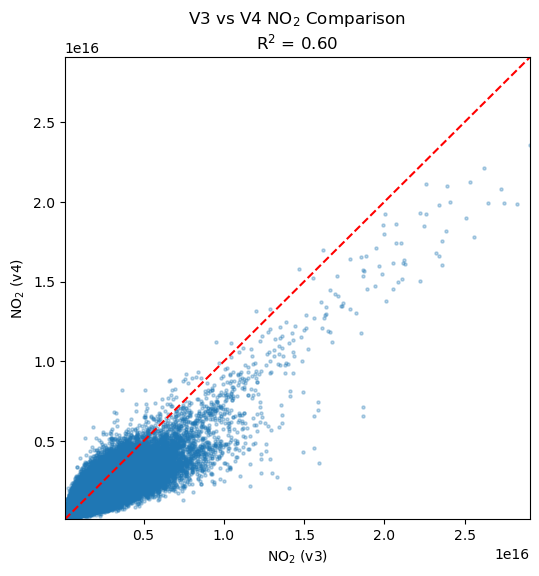

In [21]:
# drop NaNs just in case
df = merged.dropna(subset=['no2_mean_v3', 'no2_mean_v4'])

# compute R and R²
r = np.corrcoef(df['no2_mean_v3'], df['no2_mean_v4'])[0, 1]
r2 = r**2

plt.figure(figsize=(6,6))

plt.scatter(
    df['no2_mean_v3'],
    df['no2_mean_v4'],
    alpha=0.3,
    s=5
)

# 1:1 line
lims = [
    min(df['no2_mean_v3'].min(), df['no2_mean_v4'].min()),
    max(df['no2_mean_v3'].max(), df['no2_mean_v4'].max())
]
plt.plot(lims, lims, 'r--')

plt.xlabel('NO$_2$ (v3)')
plt.ylabel('NO$_2$ (v4)')
plt.title(f'V3 vs V4 NO$_2$ Comparison\nR$^2$ = {r2:.2f}')

plt.xlim(lims)
plt.ylim(lims)

plt.show()

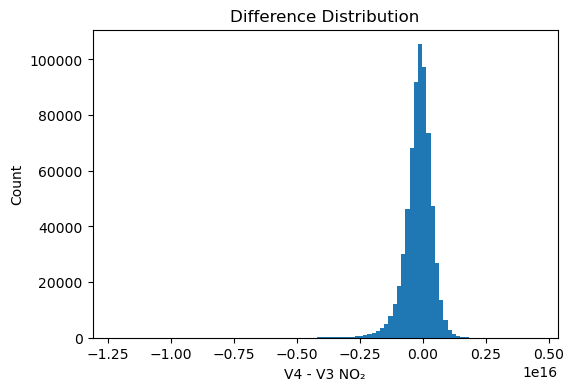

In [22]:
plt.figure(figsize=(6,4))
plt.hist(merged['diff'], bins=100)
plt.xlabel('V4 - V3 NO₂')
plt.ylabel('Count')
plt.title('Difference Distribution')
plt.show()

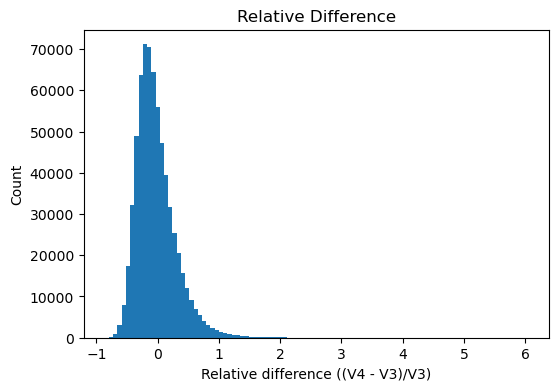

In [23]:
plt.figure(figsize=(6,4))
plt.hist(merged['rel_diff'], bins=100)
plt.xlabel('Relative difference ((V4 - V3)/V3)')
plt.ylabel('Count')
plt.title('Relative Difference')
plt.show()

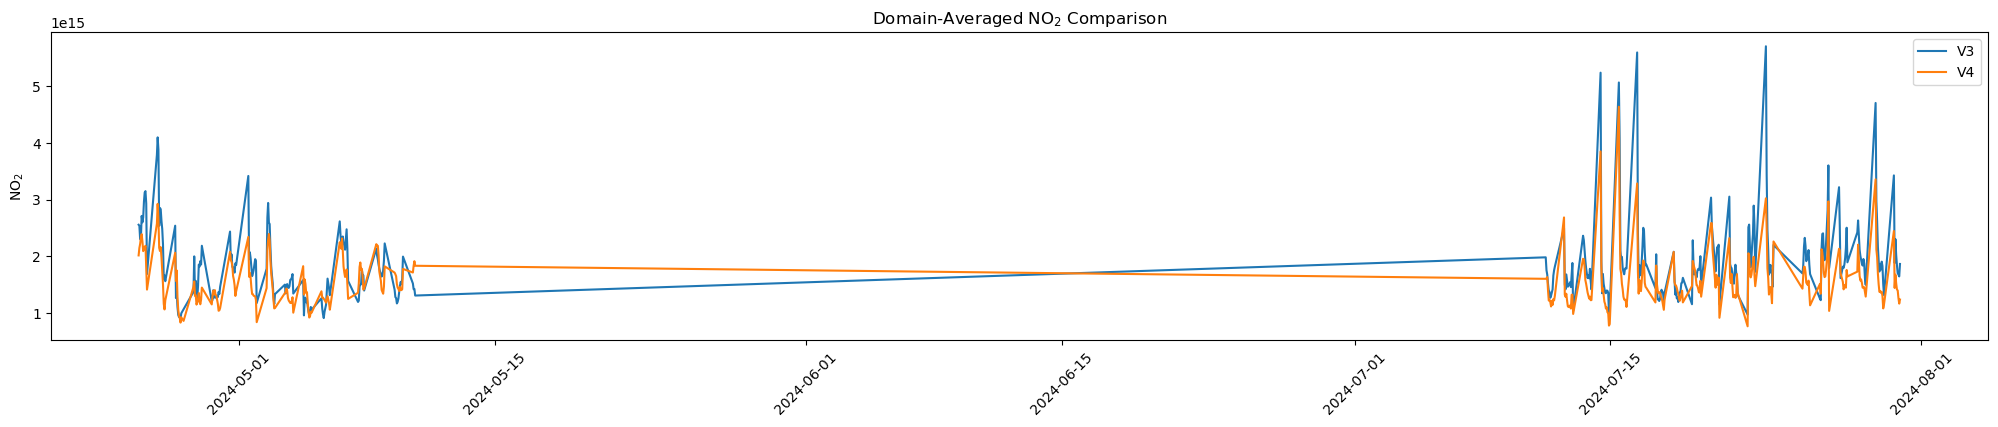

In [24]:
agg = (
    merged.groupby('datetime')
    .agg(
        v3_mean=('no2_mean_v3', 'mean'),
        v4_mean=('no2_mean_v4', 'mean')
    )
)

plt.figure(figsize=(25,4))
plt.plot(agg.index, agg['v3_mean'], label='V3')
plt.plot(agg.index, agg['v4_mean'], label='V4')

plt.legend()
plt.xticks(rotation=45)
plt.title('Domain-Averaged NO$_2$ Comparison')
plt.ylabel('NO$_2$')
plt.show()

In [25]:
merged['is_pulse'] = merged['pulse_start'] == True

In [26]:
merged.columns

Index(['datetime', 'grid_lat', 'grid_lon', 'no2_mean_v3', 'no2_std_v3',
       'no2_count_v3', 'no2_sem_v3', 'eff_cloud_fraction_mean_v3',
       'eff_cloud_fraction_std_v3', 'amf_cloud_fraction_mean_v3',
       'amf_cloud_fraction_std_v3', 'snow_ice_fraction_mean_v3',
       'snow_ice_fraction_std_v3', 'cv_no2_v3', 'rolling_mean', 'rolling_std',
       'pulse_threshold', 'above_3sd', 'prev_above', 'run_id', 'run_len',
       'pulse_start', 'datetime_local', 'hour_local', 'no2_mean_v4',
       'no2_std_v4', 'no2_count_v4', 'no2_sem_v4',
       'eff_cloud_fraction_mean_v4', 'eff_cloud_fraction_std_v4',
       'amf_cloud_fraction_mean_v4', 'amf_cloud_fraction_std_v4',
       'snow_ice_fraction_mean_v4', 'snow_ice_fraction_std_v4', 'cv_no2_v4',
       'diff', 'rel_diff', 'is_pulse'],
      dtype='object')

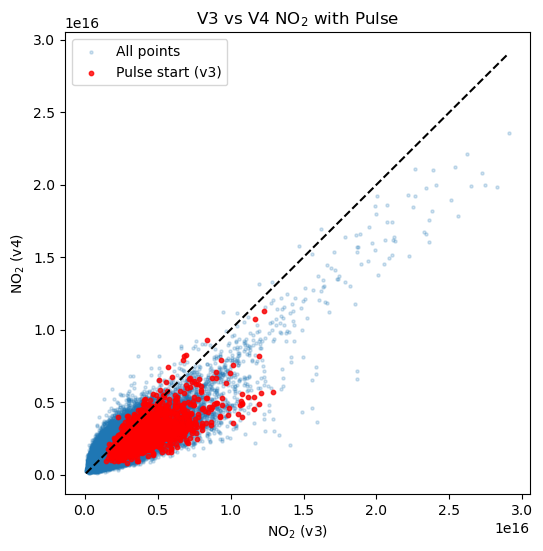

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

# background points
plt.scatter(
    merged['no2_mean_v3'],
    merged['no2_mean_v4'],
    alpha=0.2,
    s=5,
    label='All points'
)

# pulse points (highlighted)
pulse_pts = merged[merged['is_pulse']]

plt.scatter(
    pulse_pts['no2_mean_v3'],
    pulse_pts['no2_mean_v4'],
    color='red',
    s=10,
    label='Pulse start (v3)',
    alpha=0.8
)

# 1:1 line
lims = [
    min(merged['no2_mean_v3'].min(), merged['no2_mean_v4'].min()),
    max(merged['no2_mean_v3'].max(), merged['no2_mean_v4'].max())
]
plt.plot(lims, lims, 'k--')

plt.xlabel('NO$_2$ (v3)')
plt.ylabel('NO$_2$ (v4)')
plt.title('V3 vs V4 NO$_2$ with Pulse')
plt.legend()

plt.show()

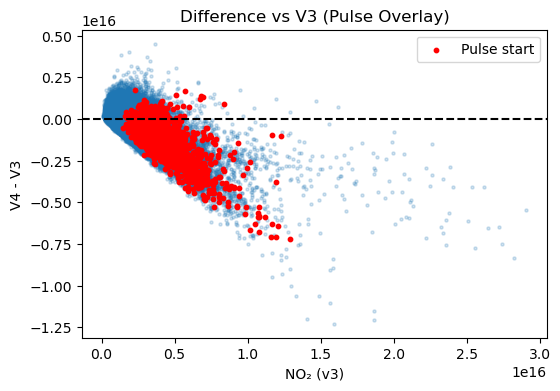

In [28]:
merged['diff'] = merged['no2_mean_v4'] - merged['no2_mean_v3']

plt.figure(figsize=(6,4))

plt.scatter(
    merged['no2_mean_v3'],
    merged['diff'],
    alpha=0.2,
    s=5
)

plt.scatter(
    pulse_pts['no2_mean_v3'],
    pulse_pts['diff'],
    color='red',
    s=10,
    label='Pulse start'
)

plt.axhline(0, linestyle='--', color='k')

plt.xlabel('NO₂ (v3)')
plt.ylabel('V4 - V3')
plt.title('Difference vs V3 (Pulse Overlay)')
plt.legend()

plt.show()

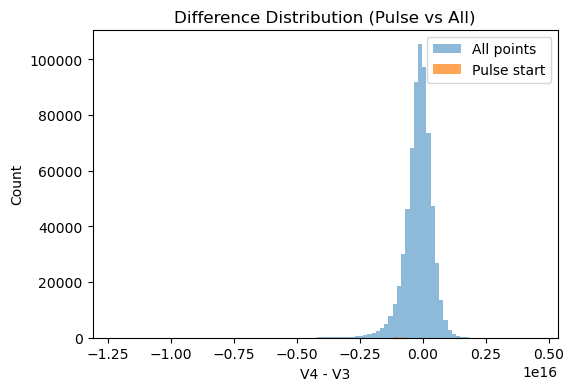

In [29]:
plt.figure(figsize=(6,4))

plt.hist(
    merged['diff'],
    bins=100,
    alpha=0.5,
    label='All points'
)

plt.hist(
    pulse_pts['diff'],
    bins=100,
    alpha=0.7,
    label='Pulse start'
)

plt.xlabel('V4 - V3')
plt.ylabel('Count')
plt.title('Difference Distribution (Pulse vs All)')
plt.legend()

plt.show()

In [30]:
pulse_pts['rel_diff'] = (pulse_pts['no2_mean_v4'] - pulse_pts['no2_mean_v3']) / pulse_pts['no2_mean_v3']

pulse_pts['rel_diff'].describe()

/tmp/ipykernel_106278/1174249315.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pulse_pts['rel_diff'] = (pulse_pts['no2_mean_v4'] - pulse_pts['no2_mean_v3']) / pulse_pts['no2_mean_v3']


count    1736.000000
mean       -0.279075
std         0.199782
min        -0.739059
25%        -0.424274
50%        -0.297138
75%        -0.149839
max         0.768069
Name: rel_diff, dtype: float64

In [31]:
merged.columns

Index(['datetime', 'grid_lat', 'grid_lon', 'no2_mean_v3', 'no2_std_v3',
       'no2_count_v3', 'no2_sem_v3', 'eff_cloud_fraction_mean_v3',
       'eff_cloud_fraction_std_v3', 'amf_cloud_fraction_mean_v3',
       'amf_cloud_fraction_std_v3', 'snow_ice_fraction_mean_v3',
       'snow_ice_fraction_std_v3', 'cv_no2_v3', 'rolling_mean', 'rolling_std',
       'pulse_threshold', 'above_3sd', 'prev_above', 'run_id', 'run_len',
       'pulse_start', 'datetime_local', 'hour_local', 'no2_mean_v4',
       'no2_std_v4', 'no2_count_v4', 'no2_sem_v4',
       'eff_cloud_fraction_mean_v4', 'eff_cloud_fraction_std_v4',
       'amf_cloud_fraction_mean_v4', 'amf_cloud_fraction_std_v4',
       'snow_ice_fraction_mean_v4', 'snow_ice_fraction_std_v4', 'cv_no2_v4',
       'diff', 'rel_diff', 'is_pulse'],
      dtype='object')

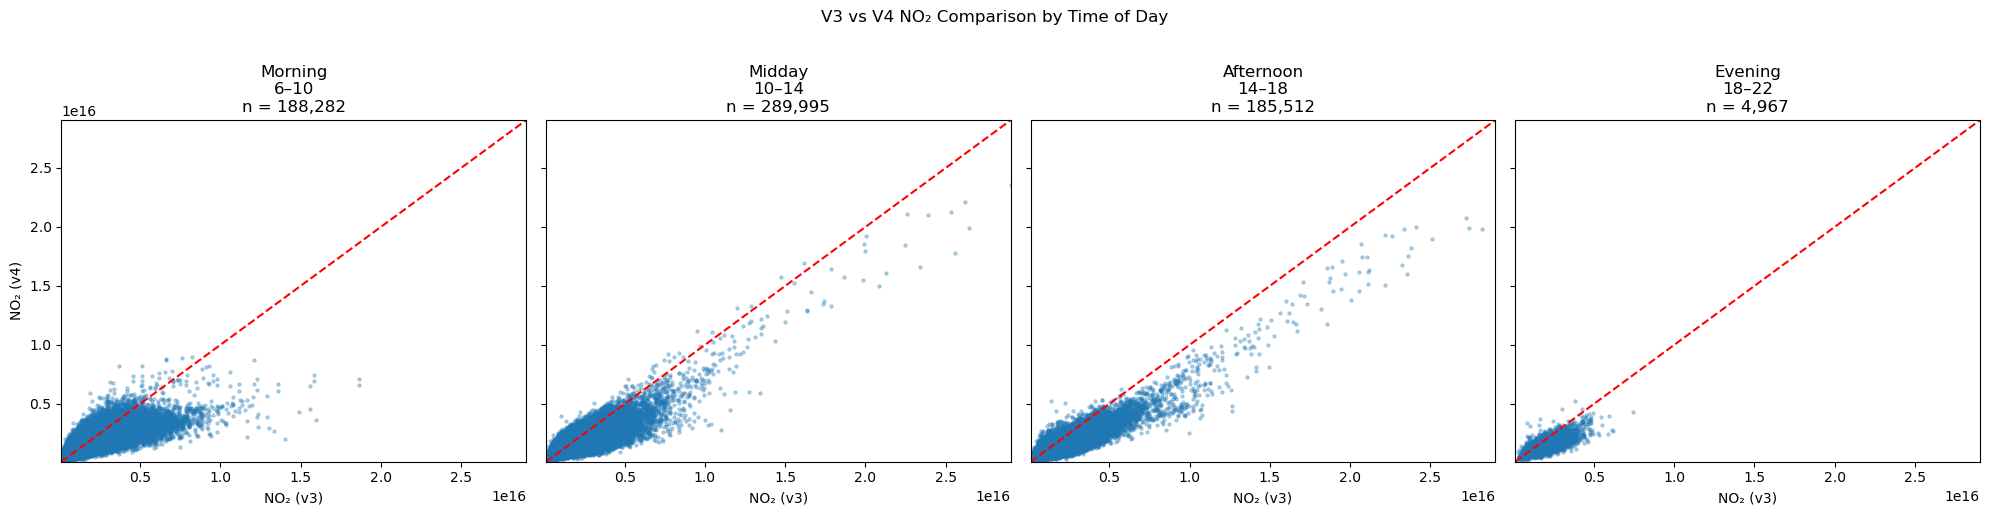

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# preserve timezone-aware datetime
merged['datetime_local'] = merged['datetime_local'].apply(pd.Timestamp)

# extract local hour correctly
merged['hour'] = merged['datetime_local'].apply(lambda x: x.hour)

# define time-of-day bins
def get_time_bin(hour):
    if 6 <= hour < 10:
        return 'Morning\n6–10'
    elif 10 <= hour < 14:
        return 'Midday\n10–14'
    elif 14 <= hour < 18:
        return 'Afternoon\n14–18'
    elif 18 <= hour < 22:
        return 'Evening\n18–22'
    else:
        return 'Night\n22–6'

merged['time_bin'] = merged['hour'].apply(get_time_bin)
time_bins = ['Morning\n6–10', 'Midday\n10–14', 'Afternoon\n14–18', 'Evening\n18–22']

# compute shared axis limits with some padding
all_vals = pd.concat([merged['no2_mean_v3'], merged['no2_mean_v4']]).dropna()
lims = [all_vals.min(), all_vals.max()]

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)

for ax, tb in zip(axes, time_bins):
    subset = merged[merged['time_bin'] == tb].dropna(subset=['no2_mean_v3', 'no2_mean_v4'])
    
    ax.scatter(
        subset['no2_mean_v3'],
        subset['no2_mean_v4'],
        alpha=0.3,
        s=5
    )
    ax.plot(lims, lims, 'r--', linewidth=1.5, label='1:1 line')
    ax.set_title(f'{tb}\nn = {len(subset):,}')
    ax.set_xlim(lims)
    ax.set_ylim(lims)

for ax in axes:
    ax.set_xlabel('NO₂ (v3)')

axes[0].set_ylabel('NO₂ (v4)')
fig.suptitle('V3 vs V4 NO₂ Comparison by Time of Day', y=1.02)
plt.tight_layout()
plt.show()

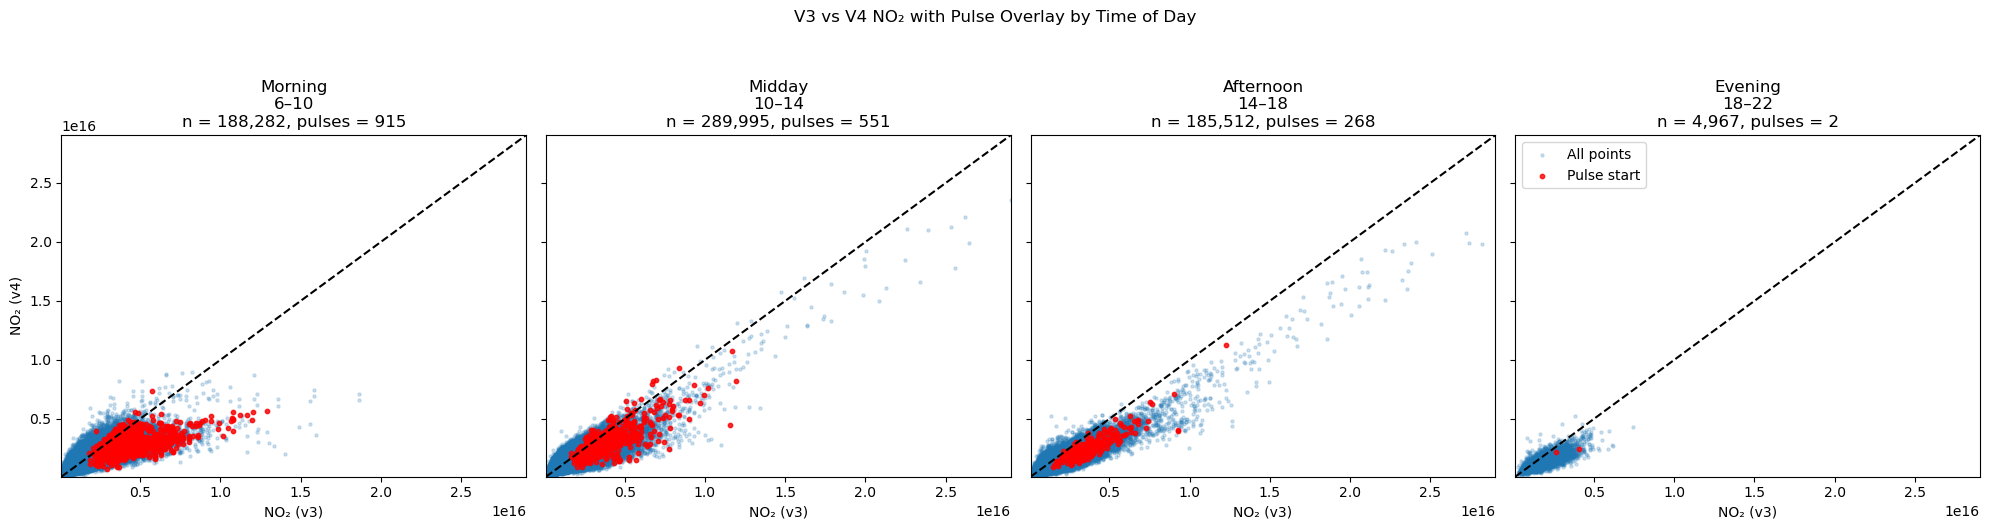

In [33]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)

for ax, tb in zip(axes, time_bins):
    subset = merged[merged['time_bin'] == tb]
    pulses = subset[subset['pulse_start'] == True]

    ax.scatter(
        subset['no2_mean_v3'],
        subset['no2_mean_v4'],
        alpha=0.2,
        s=5,
        label='All points'
    )

    ax.scatter(
        pulses['no2_mean_v3'],
        pulses['no2_mean_v4'],
        color='red',
        alpha=0.8,
        s=10,
        label='Pulse start'
    )

    ax.plot(lims, lims, 'k--')
    ax.set_title(f'{tb}\nn = {len(subset):,}, pulses = {len(pulses):,}')
    ax.set_xlim(lims)
    ax.set_ylim(lims)

for ax in axes:
    ax.set_xlabel('NO₂ (v3)')

axes[0].set_ylabel('NO₂ (v4)')
axes[-1].legend()

fig.suptitle('V3 vs V4 NO₂ with Pulse Overlay by Time of Day', y=1.05)
plt.tight_layout()
plt.show()

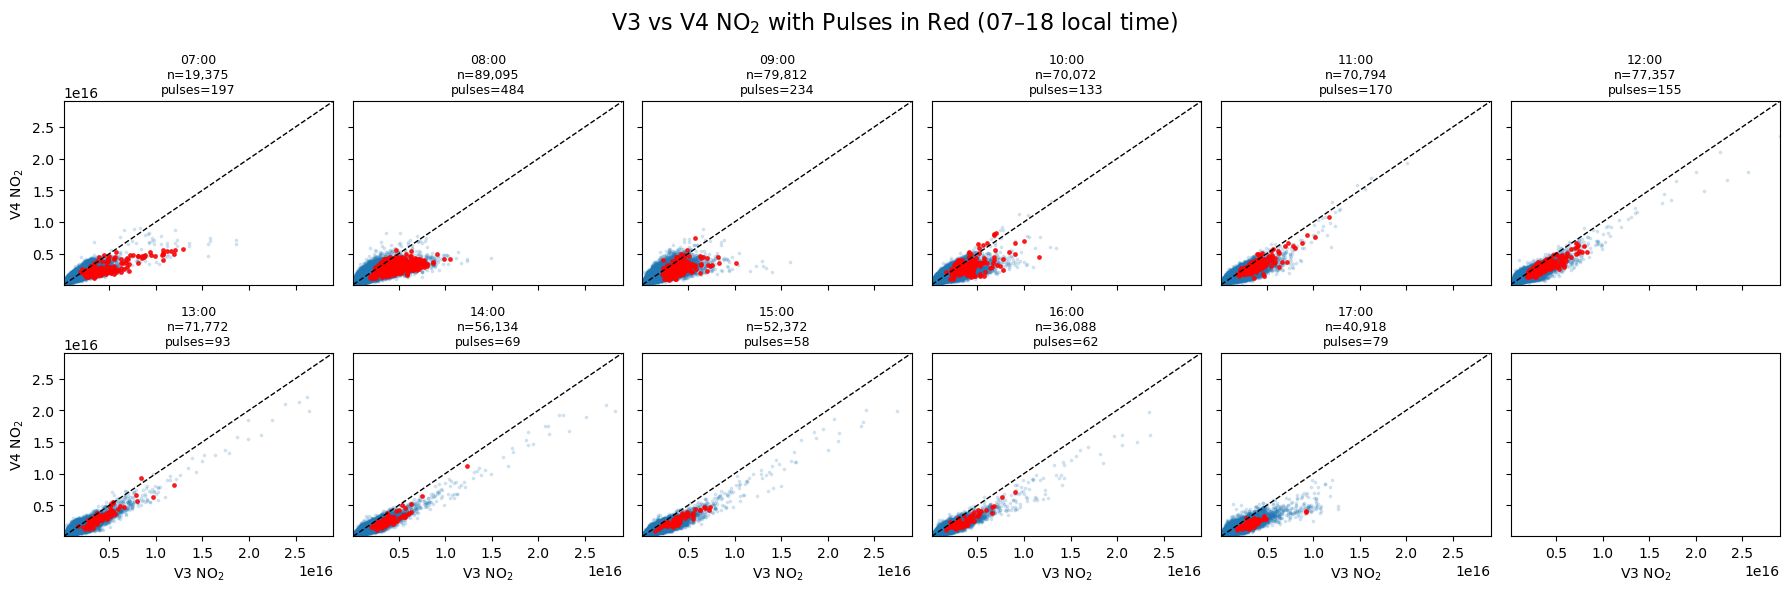

In [38]:
hours = list(range(7, 18))  # 7–18 inclusive

fig, axes = plt.subplots(2, 6, figsize=(18, 6), sharex=True, sharey=True)
axes = axes.flatten()

for i, h in enumerate(hours):
    ax = axes[i]
    subset = merged[merged['hour'] == h]
    pulses = subset[subset['pulse_start'] == True]

    # background
    ax.scatter(
        subset['no2_mean_v3'],
        subset['no2_mean_v4'],
        alpha=0.15,
        s=3
    )

    # pulses
    ax.scatter(
        pulses['no2_mean_v3'],
        pulses['no2_mean_v4'],
        color='red',
        alpha=0.8,
        s=6
    )

    # 1:1 line
    ax.plot(lims, lims, 'k--', linewidth=1)

    ax.set_title(f'{h:02d}:00\nn={len(subset):,}\npulses={len(pulses):,}', fontsize=9)
    ax.set_xlim(lims)
    ax.set_ylim(lims)

# label only outer axes (cleaner)
for ax in axes[6:]:
    ax.set_xlabel('V3 NO$_2$')

for ax in axes[::6]:
    ax.set_ylabel('V4 NO$_2$')

fig.suptitle('V3 vs V4 NO$_2$ with Pulses in Red (07–18 local time)', fontsize=16)
plt.tight_layout()
plt.show()

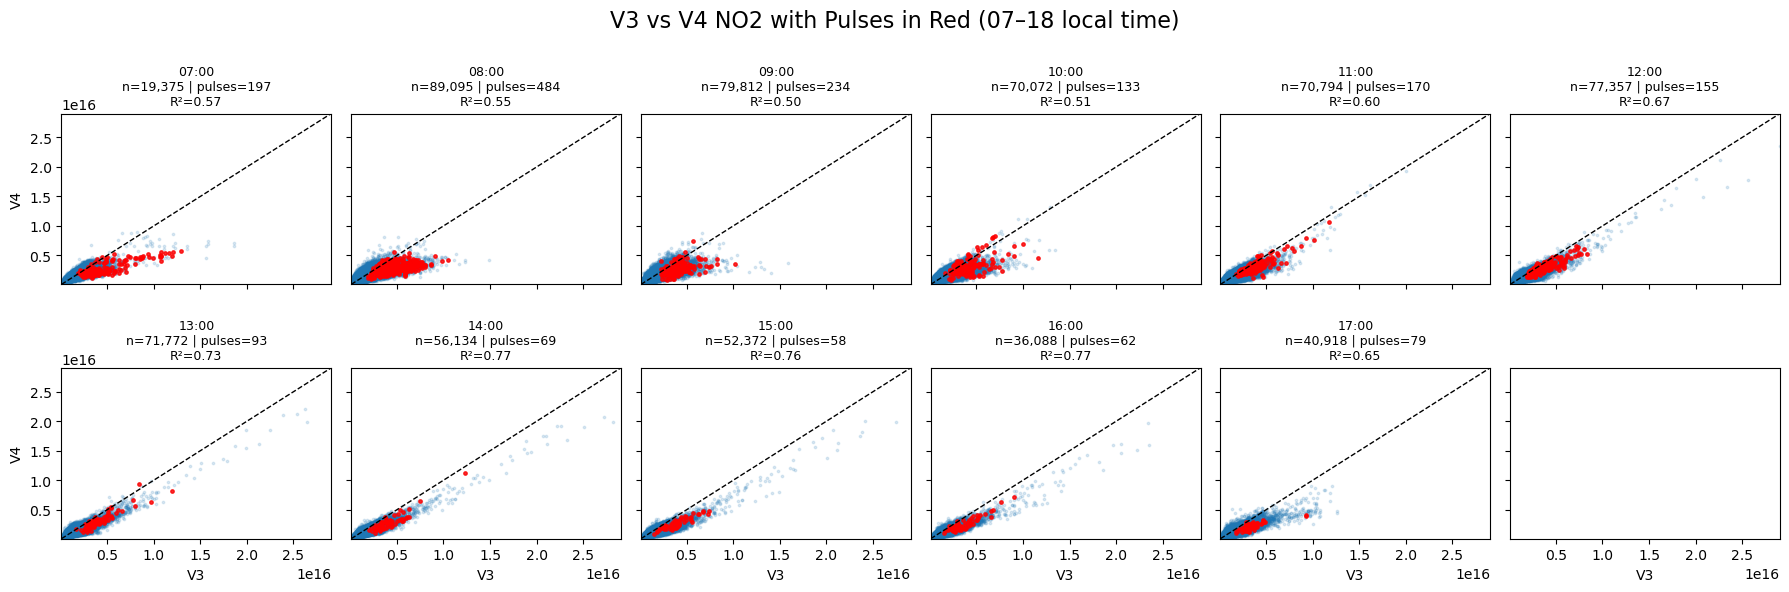

In [39]:
import numpy as np
import matplotlib.pyplot as plt

hours = list(range(7, 18))  # 7–18 inclusive

fig, axes = plt.subplots(2, 6, figsize=(18, 6), sharex=True, sharey=True)
axes = axes.flatten()

r2_dict = {}  # store values if you want later

for i, h in enumerate(hours):
    ax = axes[i]
    subset = merged[merged['hour'] == h]

    # drop NaNs just in case
    subset = subset.dropna(subset=['no2_mean_v3', 'no2_mean_v4'])

    pulses = subset[subset['pulse_start'] == True]

    #compute R2
    if len(subset) > 2:
        r = np.corrcoef(subset['no2_mean_v3'], subset['no2_mean_v4'])[0, 1]
        r2 = r**2
    else:
        r2 = np.nan

    r2_dict[h] = r2

    # background
    ax.scatter(
        subset['no2_mean_v3'],
        subset['no2_mean_v4'],
        alpha=0.15,
        s=3
    )

    # pulses
    ax.scatter(
        pulses['no2_mean_v3'],
        pulses['no2_mean_v4'],
        color='red',
        alpha=0.8,
        s=6
    )

    # 1:1 line
    ax.plot(lims, lims, 'k--', linewidth=1)
    ax.set_title(
        f'{h:02d}:00\nn={len(subset):,} | pulses={len(pulses):,}\nR²={r2:.2f}',
        fontsize=9
    )

    ax.set_xlim(lims)
    ax.set_ylim(lims)

# axis labels
for ax in axes[6:]:
    ax.set_xlabel('V3')

for ax in axes[::6]:
    ax.set_ylabel('V4')

fig.suptitle('V3 vs V4 NO2 with Pulses in Red (07–18 local time)', fontsize=16)
plt.tight_layout()
plt.show()

# creating scaling factors for each hour

In [41]:
from scipy import stats

# ── Per-hour scaling factors ──────────────────────────────────────────────────
# For each hour we fit three estimators:
#   1. Median ratio  : robust, no intercept — good when outliers are present
#   2. OLS + intercept: standard linear regression
#   3. OLS through origin: least-squares slope forced through (0,0)
#
# To bring V4 onto the 1:1 line with V3, divide V4 by the slope (or ratio).
hours = list(range(7, 19))

records = []
for h in hours:
    sub = merged[merged["hour"] == h].dropna(subset=["no2_mean_v3", "no2_mean_v4"])
    x = sub["no2_mean_v3"].values
    y = sub["no2_mean_v4"].values

    if len(sub) < 5:
        continue

    # 1. Median ratio (robust to outliers)
    ratio_mask = x > 0
    median_ratio = np.median(y[ratio_mask] / x[ratio_mask])

    # 2. OLS with intercept
    slope_ols, intercept_ols, r, p, se = stats.linregress(x, y)
    r2_ols = r**2

    # 3. Least-squares through origin: slope = Σ(x·y) / Σ(x²)
    slope_origin = np.dot(x, y) / np.dot(x, x)

    records.append(dict(
        hour=h,
        n=len(sub),
        median_ratio=median_ratio,
        slope_ols=slope_ols,
        intercept_ols=intercept_ols,
        r2_ols=r2_ols,
        slope_origin=slope_origin,
    ))

scaling_df = pd.DataFrame(records)
print(scaling_df.to_string(index=False, float_format="{:.4f}".format))

 hour     n  median_ratio  slope_ols        intercept_ols  r2_ols  slope_origin
    7 19375        1.0562     0.4820 844673178318585.8750  0.5661        0.8319
    8 89095        1.0777     0.5267 765690078615746.5000  0.5524        0.8754
    9 79812        1.0426     0.5269 808517341887562.3750  0.4966        0.8941
   10 70072        1.0074     0.5198 721274273680601.0000  0.5121        0.8668
   11 70794        0.9537     0.5821 543720152662936.7500  0.5974        0.8551
   12 77357        0.9001     0.6214 423185898571035.8750  0.6730        0.8345
   13 71772        0.8652     0.6486 330527398389732.6250  0.7348        0.8131
   14 56134        0.8182     0.6371 278345544250004.0000  0.7743        0.7703
   15 52372        0.7936     0.6008 295150745564498.1250  0.7568        0.7393
   16 36088        0.7804     0.5985 285741381817881.2500  0.7704        0.7285
   17 40918        0.8318     0.5321 435230887883374.3750  0.6513        0.7418
   18  4967        0.7833     0.5338 418

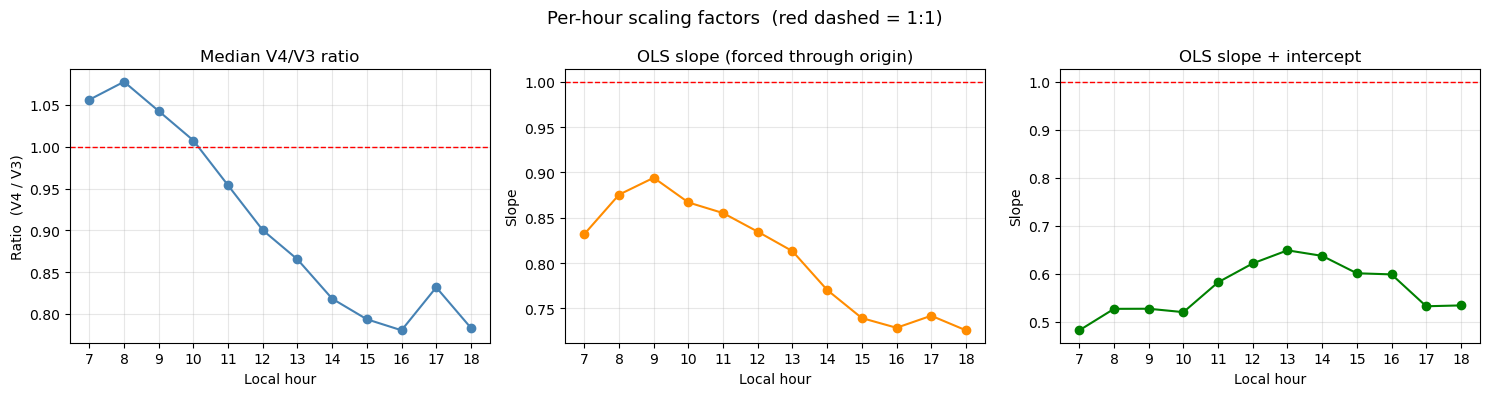

In [42]:
# ── Visualise per-hour scaling factors ───────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)

axes[0].plot(scaling_df["hour"], scaling_df["median_ratio"], "o-", color="steelblue")
axes[0].axhline(1, color="red", linestyle="--", linewidth=1)
axes[0].set_title("Median V4/V3 ratio")
axes[0].set_ylabel("Ratio  (V4 / V3)")

axes[1].plot(scaling_df["hour"], scaling_df["slope_origin"], "o-", color="darkorange")
axes[1].axhline(1, color="red", linestyle="--", linewidth=1)
axes[1].set_title("OLS slope (forced through origin)")
axes[1].set_ylabel("Slope")

axes[2].plot(scaling_df["hour"], scaling_df["slope_ols"], "o-", color="green")
axes[2].axhline(1, color="red", linestyle="--", linewidth=1)
axes[2].set_title("OLS slope + intercept")
axes[2].set_ylabel("Slope")

for ax in axes:
    ax.set_xlabel("Local hour")
    ax.set_xticks(scaling_df["hour"])
    ax.grid(True, alpha=0.3)

fig.suptitle("Per-hour scaling factors  (red dashed = 1:1)", fontsize=13)
plt.tight_layout()
plt.show()

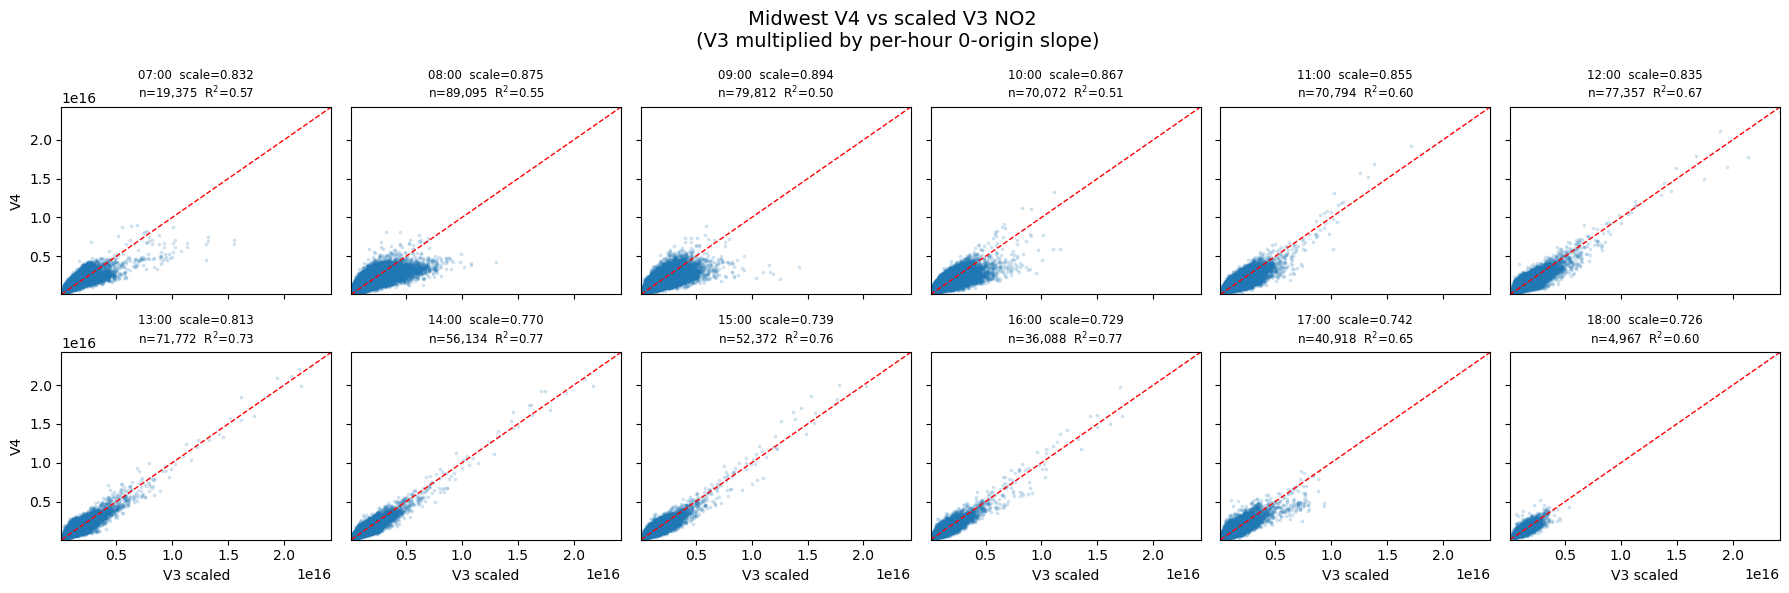

In [43]:
# ── Apply per-hour scaling to V3 and re-plot ──────────────────────────────────
# V4 is left untouched. V3 is scaled down by the per-hour OLS-origin slope,
# so that scaled V3 ≈ V4 on the 1:1 line.
# Swap "slope_origin" → "median_ratio" in scaling_df if preferred.
scale_map = dict(zip(scaling_df["hour"], scaling_df["slope_origin"]))

merged["no2_v3_scaled"] = merged.apply(
    lambda row: row["no2_mean_v3"] * scale_map[row["hour"]]
    if row["hour"] in scale_map else np.nan,
    axis=1
)

lims_scaled = [
    min(merged["no2_v3_scaled"].min(), merged["no2_mean_v4"].min()),
    max(merged["no2_v3_scaled"].max(), merged["no2_mean_v4"].max())
]

fig, axes = plt.subplots(2, 6, figsize=(18, 6), sharex=True, sharey=True)
axes = axes.flatten()

for i, h in enumerate(hours):
    ax = axes[i]
    subset = merged[merged["hour"] == h].dropna(subset=["no2_v3_scaled", "no2_mean_v4"])
    sf = scale_map.get(h, float("nan"))

    ax.scatter(subset["no2_v3_scaled"], subset["no2_mean_v4"], alpha=0.15, s=3)
    ax.plot(lims_scaled, lims_scaled, "r--", linewidth=1)

    r = np.corrcoef(subset["no2_v3_scaled"], subset["no2_mean_v4"])[0, 1]
    r2 = r**2

    ax.set_title(
        f"{h:02d}:00  scale={sf:.3f}\nn={len(subset):,}  R$^2$={r2:.2f}",
        fontsize=8.5
    )
    ax.set_xlim(lims_scaled)
    ax.set_ylim(lims_scaled)

for ax in axes[6:]:
    ax.set_xlabel("V3 scaled")
for ax in axes[::6]:
    ax.set_ylabel("V4")

fig.suptitle(" Midwest V4 vs scaled V3 NO2  \n (V3 multiplied by per-hour 0-origin slope)", fontsize=14)
plt.tight_layout()
plt.show()

In [44]:
scaling_df

,hour,n,median_ratio,slope_ols,intercept_ols,r2_ols,slope_origin
0,7,19375,1.056197,0.481975,8.446732e+14,0.566050,0.831940
1,8,89095,1.077682,0.526694,7.656901e+14,0.552367,0.875446
2,9,79812,1.042624,0.526900,8.085173e+14,0.496593,0.894077
3,10,70072,1.007424,0.519804,7.212743e+14,0.512117,0.866824
4,11,70794,0.953716,0.582076,5.437202e+14,0.597423,0.855114
5,12,77357,0.900121,0.621433,4.231859e+14,0.673033,0.834543
6,13,71772,0.865226,0.648644,3.305274e+14,0.734756,0.813060
7,14,56134,0.818199,0.637103,2.783455e+14,0.774251,0.770254
8,15,52372,0.793600,0.600836,2.951507e+14,0.756838,0.739253
9,16,36088,0.780423,0.598495,2.857414e+14,0.770366,0.728544


In [45]:
scaling_df_filtered = scaling_df.drop(columns={'median_ratio','slope_ols','intercept_ols','r2_ols'})

In [46]:
scaling_df_filtered

,hour,n,slope_origin
0,7,19375,0.831940
1,8,89095,0.875446
2,9,79812,0.894077
3,10,70072,0.866824
4,11,70794,0.855114
5,12,77357,0.834543
6,13,71772,0.813060
7,14,56134,0.770254
8,15,52372,0.739253
9,16,36088,0.728544


In [47]:
#saving 
scaling_df_filtered.to_parquet("/global/scratch/users/toireasamarie/Scaling Factors/low_CF_scaling_by_hour.parquet", engine='pyarrow')
print("Saved: /global/scratch/users/toireasamarie/Scaling Factors/low_CF_scaling_by_hour.parquet")


Saved: /global/scratch/users/toireasamarie/Scaling Factors/low_CF_scaling_by_hour.parquet
